In [1]:
# Reimports

import sys
sys.path.append("../src")

import numpy as np
import pandas as pd

from linreg.preprocessing import (
    NUMERICAL_COLS, split_by_date, fit_one_hot, transform_one_hot, fit_scaler, transform_scaler,
)
from linreg.models import LinearRegressionNormal

df = pd.read_csv("../data/processed/bart_daily.csv", parse_dates=["date"])

train, test = split_by_date(df)

categories = fit_one_hot(train)
train_enc = transform_one_hot(train, categories)
test_enc = transform_one_hot(test, categories)

stats = fit_scaler(train_enc)
train_ready = transform_scaler(train_enc, stats)
test_ready = transform_scaler(test_enc, stats)

print(train_ready.shape, test_ready.shape)

(2928, 29) (2920, 29)


In [2]:
feature_cols = [c for c in train_ready.columns if c not in ("date", "exits")]

X_train = train_ready[feature_cols].to_numpy(dtype=float)
y_train = train_ready["exits"].to_numpy(dtype=float)
X_test = test_ready[feature_cols].to_numpy(dtype=float)
y_test = test_ready["exits"].to_numpy(dtype=float)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(2928, 27) (2928,) (2920, 27) (2920,)


In [3]:
model = LinearRegressionNormal().fit(X_train, y_train)
preds = model.predict(X_test)

print("coef_ shape:", model.coef_.shape)
print("intercept_:", round(model.intercept_))
print("preds shape:", preds.shape)

coef_ shape: (27,)
intercept_: 3698
preds shape: (2920,)


In [4]:
from sklearn.linear_model import LinearRegression

sk = LinearRegression().fit(X_train, y_train)

print("Intercepts match:", np.isclose(model.intercept_, sk.intercept_))
print("Coefficients match:", np.allclose(model.coef_, sk.coef_))
print("Predictions match:", np.allclose(preds, sk.predict(X_test)))

Intercepts match: True
Coefficients match: True
Predictions match: True


In [5]:
coefs = pd.Series(model.coef_, index=feature_cols).round()
coefs.sort_values()

is_holiday              -4503.0
day_of_week_Sunday      -3909.0
day_of_week_Saturday    -2496.0
precip_in                -184.0
month_12                  -88.0
month_7                    63.0
temp_max_f                102.0
day_of_week_Monday        254.0
month_11                  286.0
month_4                   406.0
month_8                   437.0
month_3                   496.0
month_5                   546.0
month_2                   570.0
month_6                   671.0
station_24TH              760.0
station_DBRK              792.0
station_16TH              917.0
month_10                  986.0
month_9                  1047.0
day_of_week_Thursday     1916.0
day_of_week_Tuesday      2017.0
day_of_week_Wednesday    2080.0
station_CIVC             3490.0
station_POWL             5900.0
station_MONT             6843.0
station_EMBR             9696.0
dtype: float64

In [6]:
# Testing if metrics.py works

from linreg.metrics import *

y_true = [8000, 5000, 12000]
y_pred = [7000, 5500, 9000]

print(mae(y_true, y_pred))    # 1500.0
print(mse(y_true, y_pred))    # 3416666.67
print(rmse(y_true, y_pred))   # 1848.4
print(r2(y_true, y_pred))     # ~ 0.58

print(r2([5, 5, 5], [5, 5, 5]))   # 1.0 (constant target, perfect)
print(r2([5, 5, 5], [4, 5, 6]))   # 0.0 (constant target, not perfect)

1500.0
3416666.6666666665
1848.422751068236
0.5844594594594594
1.0
0.0


In [7]:
# Real model

print(f"Test RMSE: {rmse(y_test, preds):,.0f}")
print(f"Test MAE:  {mae(y_test, preds):,.0f}")
print(f"Test R²:   {r2(y_test, preds):.3f}")

Test RMSE: 2,421
Test MAE:  1,747
Test R²:   0.756


In [8]:
from linreg.models import LinearRegressionGD

gd = LinearRegressionGD(lr=0.1, epochs=500, method="batch").fit(X_train, y_train)
print(len(gd.loss_history_), gd.loss_history_[0], gd.loss_history_[-1])
print(np.round(gd.coef_[:5]))
print(np.round(model.coef_[:5]))   # normal equation, for comparison

# coefficients are close to the normal equation but is_holiday is still off (-3251, -4503)

500 31556020.467433933 2206728.5564119983
[  168.  -183. -3251.   295. -2242.]
[  102.  -184. -4503.   254. -2496.]


In [9]:
# Testing all 3 methods

for method in ["batch", "sgd", "minibatch"]:
    gd = LinearRegressionGD(lr=0.01, epochs=20, method=method, seed=0).fit(X_train, y_train)
    test_r2 = r2(y_test, gd.predict(X_test))
    print(f"{method:>9}: final loss {gd.loss_history_[-1]:,.0f}, test R² {test_r2:.3f}")

    batch: final loss 26,606,574, test R² -1.577
      sgd: final loss 2,074,579, test R² 0.758
minibatch: final loss 2,592,038, test R² 0.701


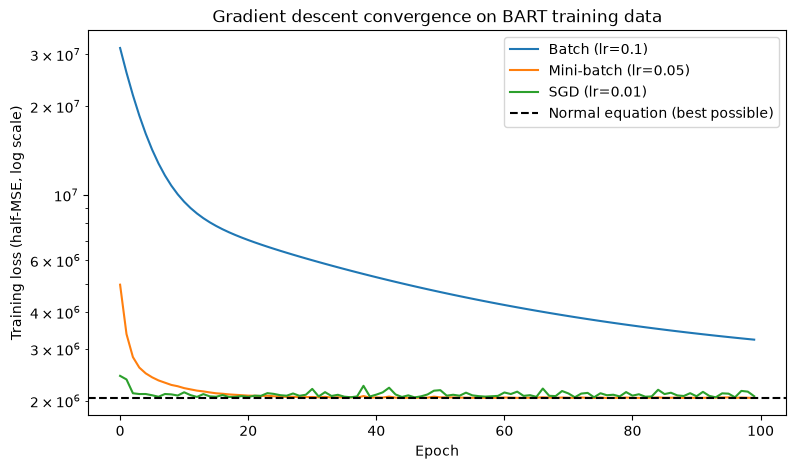

In [10]:
import matplotlib.pyplot as plt
from linreg.models import LinearRegressionGD
from linreg.metrics import mse, rmse, mae, r2

runs = {
    "Batch (lr=0.1)": LinearRegressionGD(lr=0.1, epochs=100, method="batch", seed=0),
    "Mini-batch (lr=0.05)": LinearRegressionGD(lr=0.05, epochs=100, method="minibatch", seed=0),
    "SGD (lr=0.01)": LinearRegressionGD(lr=0.01, epochs=100, method="sgd", seed=0),
}
for model_gd in runs.values():
    model_gd.fit(X_train, y_train)

# The best possible training loss, from the normal equation
best_loss = mse(y_train, model.predict(X_train)) / 2

plt.figure(figsize=(9, 5))
for name, model_gd in runs.items():
    plt.plot(model_gd.loss_history_, label=name)
plt.axhline(best_loss, color="black", linestyle="--", label="Normal equation (best possible)")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training loss (half-MSE, log scale)")
plt.title("Gradient descent convergence on BART training data")
plt.legend()
plt.savefig("../figures/loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

lr=0.001  final loss 2.25e+07  (11× the best possible)
lr=0.01   final loss 6.11e+06  (2.99× the best possible)
lr=0.1    final loss 2.37e+06  (1.16× the best possible)
lr=1.0    final loss 2.04e+06  (1× the best possible)
lr=2.0    final loss 2.82e+156  (1.38e+150× the best possible)


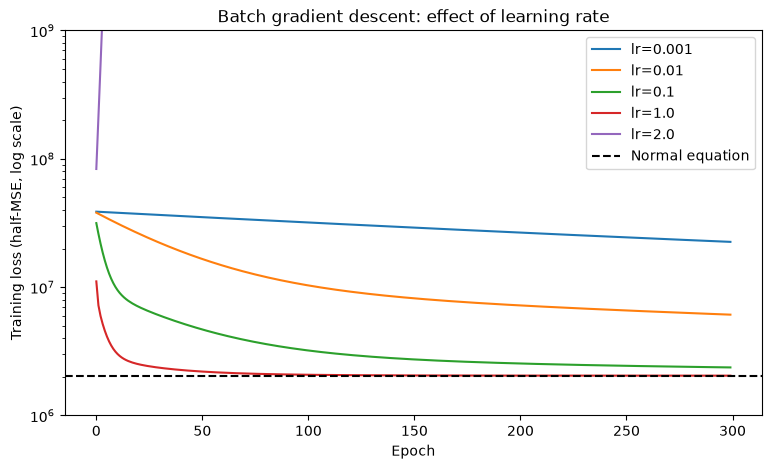

In [11]:
learning_rates = [0.001, 0.01, 0.1, 1.0, 2.0]

plt.figure(figsize=(9, 5))
for lr in learning_rates:
    gd = LinearRegressionGD(lr=lr, epochs=300, method="batch").fit(X_train, y_train)
    final = gd.loss_history_[-1]
    print(f"lr={lr:<6} final loss {final:.3g}  ({final / best_loss:.3g}× the best possible)")
    plt.plot(gd.loss_history_, label=f"lr={lr}")

plt.axhline(best_loss, color="black", linestyle="--", label="Normal equation")
plt.yscale("log")
plt.ylim(1e6, 1e9)
plt.xlabel("Epoch")
plt.ylabel("Training loss (half-MSE, log scale)")
plt.title("Batch gradient descent: effect of learning rate")
plt.legend()
plt.savefig("../figures/learning_rate_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
X_train_raw = train_enc[feature_cols].to_numpy(dtype=float)

for label, X in [("Scaled", X_train), ("Unscaled", X_train_raw)]:
    for lr in [0.1, 0.01, 0.001, 0.0001]:
        gd = LinearRegressionGD(lr=lr, epochs=300, method="batch").fit(X, y_train)
        final = gd.loss_history_[-1]
        status = "diverged" if not np.isfinite(final) or final > 1e12 else f"{final / best_loss:.3g}× best"
        print(f"{label:<9} lr={lr:<7} {status}")

Scaled    lr=0.1     1.16× best
Scaled    lr=0.01    2.99× best
Scaled    lr=0.001   11× best
Scaled    lr=0.0001  17.9× best
Unscaled  lr=0.1     diverged
Unscaled  lr=0.01    diverged
Unscaled  lr=0.001   diverged
Unscaled  lr=0.0001  5.1× best


c:\Users\ayedg\OneDrive\Documents\GitHub\bart-ridership-regression\notebooks\../src\linreg\models.py:80: RuntimeWarning: overflow encountered in square
  loss = (full_errors ** 2).mean() / 2
c:\Users\ayedg\OneDrive\Documents\GitHub\bart-ridership-regression\.venv\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


In [13]:
final_models = {
    "Normal equation": model,
    "Batch GD (lr=1.0)": LinearRegressionGD(lr=1.0, epochs=300, method="batch").fit(X_train, y_train),
    "Mini-batch GD (lr=0.05)": LinearRegressionGD(lr=0.05, epochs=100, method="minibatch", seed=0).fit(X_train, y_train),
    "SGD (lr=0.01)": LinearRegressionGD(lr=0.01, epochs=100, method="sgd", seed=0).fit(X_train, y_train),
    "scikit-learn": sk,
}

results = pd.DataFrame({
    name: {
        "RMSE": rmse(y_test, m.predict(X_test)),
        "MAE": mae(y_test, m.predict(X_test)),
        "R²": r2(y_test, m.predict(X_test)),
    }
    for name, m in final_models.items()
}).T

results.round({"RMSE": 0, "MAE": 0, "R²": 4})

,RMSE,MAE,R²
Normal equation,2421.0,1747.0,0.7557
Batch GD (lr=1.0),2422.0,1745.0,0.7555
Mini-batch GD (lr=0.05),2425.0,1751.0,0.7549
SGD (lr=0.01),2459.0,1787.0,0.7480
scikit-learn,2421.0,1747.0,0.7557


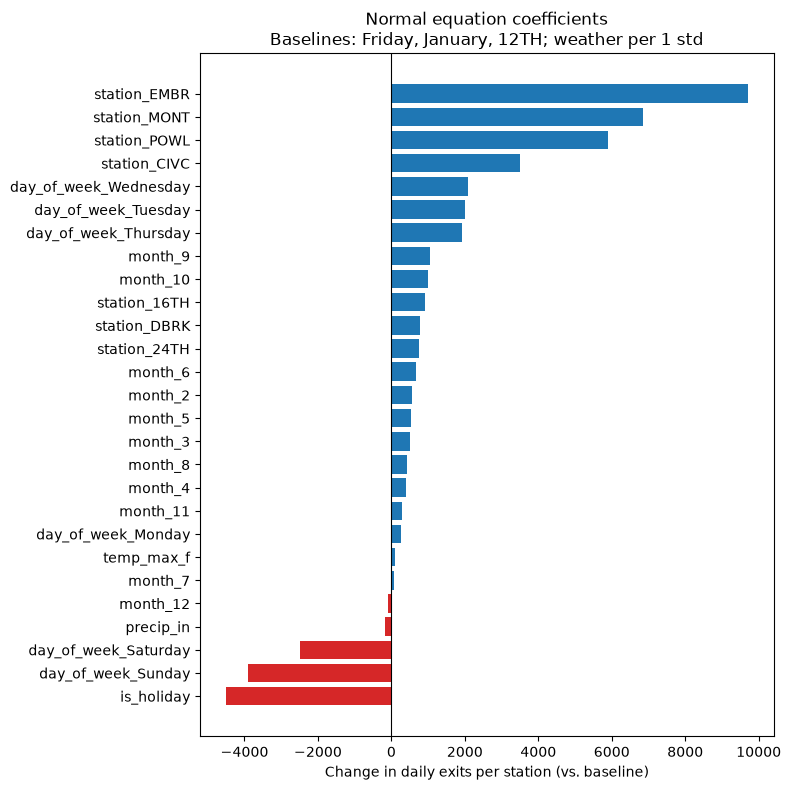

In [14]:
coefs = pd.Series(model.coef_, index=feature_cols).sort_values()

colors = ["tab:red" if c < 0 else "tab:blue" for c in coefs]

plt.figure(figsize=(8, 8))
plt.barh(coefs.index, coefs.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Change in daily exits per station (vs. baseline)")
plt.title("Normal equation coefficients\nBaselines: Friday, January, 12TH; weather per 1 std")
plt.tight_layout()
plt.savefig("../figures/coefficients.png", dpi=150, bbox_inches="tight")
plt.show()